In [69]:
from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
import astropy
import numpy as np
import os

In [70]:
os.chdir("/home/odin/Code/Course-Assignments/PH556_Astrophysics/Attempt01/data/")
print("Current working directory: {0}".format(os.getcwd()))
allDataFileNames = os.listdir()
# print("Files in current working directory: {0}".format(allDataFileNames))
print(allDataFileNames)


Current working directory: /home/odin/Code/Course-Assignments/PH556_Astrophysics/Attempt01/data
['20210721192429-359-RA.wcs.proc.fits', '20210721191920-421-RA.wcs.proc.fits', '20210713215458-181-RA.wcs.proc.fits', '20210721193447-216-RA.wcs.proc.fits', '20210721191411-345-RA.wcs.proc.fits', '20210713220516-046-RA.wcs.proc.fits', '20210721194505-080-RA.wcs.proc.fits', '20210713213912-742-RA.wcs.proc.fits', '20210713214440-179-RA.wcs.proc.fits', '20210713214949-265-RA.wcs.proc.fits', '20210713221024-980-RA.wcs.proc.fits', '20210714213919-746-RA.wcs.proc.fits', '20210713221533-914-RA.wcs.proc.fits', '20210721195014-013-RA.wcs.proc.fits', '20210714220020-444-RA.wcs.proc.fits']


In [71]:
# file1name = "data/20210713213912-742-RA.wcs.proc.fits"
# file2name = "data/20210721195014-013-RA.wcs.proc.fits"
# file1 = fits.open(file1name)
# file1.info()
files = [fits.open(filename) for filename in allDataFileNames]


In [72]:
# file2 = fits.open(file2name)
# file2.info()
files[0].info()

Filename: 20210721192429-359-RA.wcs.proc.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     253   (4096, 4108)   float32   


In [73]:
# image1Data = file1[0].data
# image2Data = file2[0].data
# image1Data

In [74]:
# file1[0].heade
# 
files[0][0].header


SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4108                                                  
HISTORY Created with RTS2 version 0.9.5 build on May 12 2020 19:07:30.          
CTIME   =           1626895469 / exposure start (seconds since 1.1.1970)        
USEC    =               359965 / exposure start micro seconds                   
JD      =     2459417.30840825 / Modified Julian Date                           
DATE-OBS= '2021-07-21T19:24:29.359' / start of exposure                         
EXPOSURE=                 300. / exposure length in seconds                     
EXPTIME =                 300. / exposure length in seconds                     
INSTRUME= 'RTS2 spectograph'

In [75]:
def parseOBSDate(dateString):
    res1 = dateString.split("T")
    resMajor = res1[0].split("-")
    resMinor = res1[1].split(":")
    res = [float(x) for x in resMajor + resMinor]
    numVal = res[0]*(12*31)*24*60*60 + res[1]*31*24*60*60 + res[2]*24*60*60 + res[3]*60*60 + res[4]*60 + res[5]
    # print(res)
    # print(numVal)
    return [res, numVal]

In [76]:
# file2[0].header
header: astropy.io.fits.header.Header = files[0][0].header
header['DATE-OBS']

'2021-07-21T19:24:29.359'

In [77]:
parseOBSDate(header['DATE-OBS'])

[[2021.0, 7.0, 21.0, 19.0, 24.0, 29.359], 64977189869.359]

In [78]:
datesOfObservationParsed = [parseOBSDate(file[0].header['DATE-OBS']) for file in files]
datesOfObservationNumVal = [date[1] for date in datesOfObservationParsed]
datesOfObservationDateVal = [date[0] for date in datesOfObservationParsed]
argsortedIndices = np.argsort(datesOfObservationNumVal)
filesSortedByDate = [files[i] for i in argsortedIndices]
datesOfObservationParsedSorted = [datesOfObservationParsed[i] for i in argsortedIndices]
datesOfObservationNumValSorted = [datesOfObservationNumVal[i] for i in argsortedIndices]
datesOfObservationDateValSorted = [datesOfObservationDateVal[i] for i in argsortedIndices]

In [79]:
print("Dates of observation (sorted):")
for date in datesOfObservationDateValSorted:
    print(date)

Dates of observation (sorted):
[2021.0, 7.0, 13.0, 21.0, 39.0, 12.742]
[2021.0, 7.0, 13.0, 21.0, 44.0, 40.179]
[2021.0, 7.0, 13.0, 21.0, 49.0, 49.265]
[2021.0, 7.0, 13.0, 21.0, 54.0, 58.181]
[2021.0, 7.0, 13.0, 22.0, 5.0, 16.046]
[2021.0, 7.0, 13.0, 22.0, 10.0, 24.98]
[2021.0, 7.0, 13.0, 22.0, 15.0, 33.914]
[2021.0, 7.0, 14.0, 21.0, 39.0, 19.746]
[2021.0, 7.0, 14.0, 22.0, 0.0, 20.444]
[2021.0, 7.0, 21.0, 19.0, 14.0, 11.345]
[2021.0, 7.0, 21.0, 19.0, 19.0, 20.421]
[2021.0, 7.0, 21.0, 19.0, 24.0, 29.359]
[2021.0, 7.0, 21.0, 19.0, 34.0, 47.216]
[2021.0, 7.0, 21.0, 19.0, 45.0, 5.08]
[2021.0, 7.0, 21.0, 19.0, 50.0, 14.013]


In [80]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


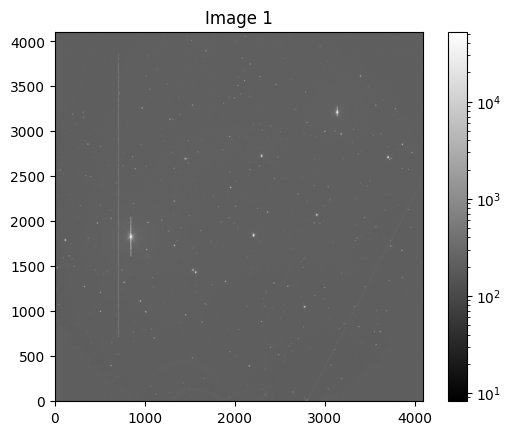

Date of above observation is: [2021.0, 7.0, 13.0, 21.0, 39.0, 12.742]


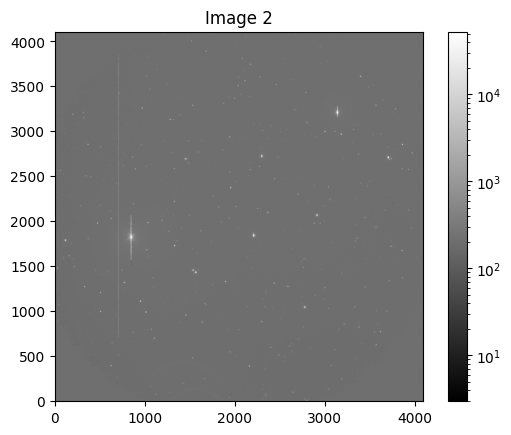

Date of above observation is: [2021.0, 7.0, 13.0, 21.0, 44.0, 40.179]


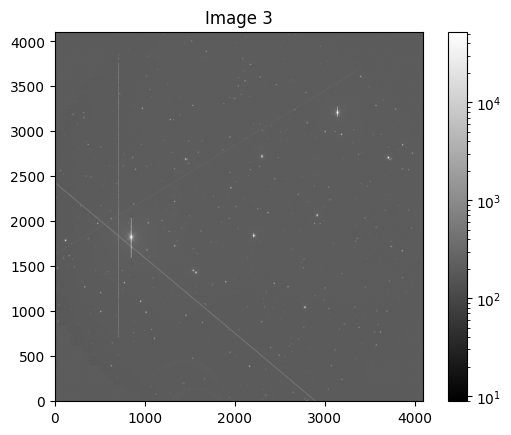

Date of above observation is: [2021.0, 7.0, 13.0, 21.0, 49.0, 49.265]


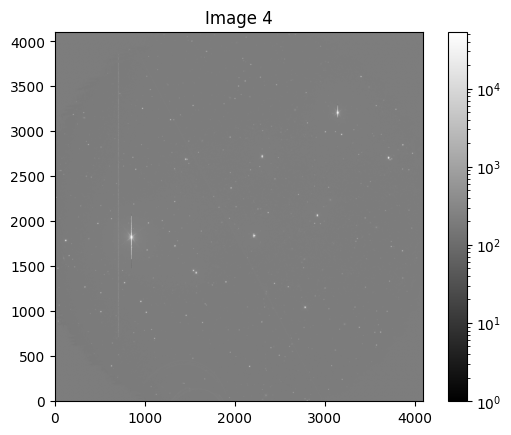

Date of above observation is: [2021.0, 7.0, 13.0, 21.0, 54.0, 58.181]


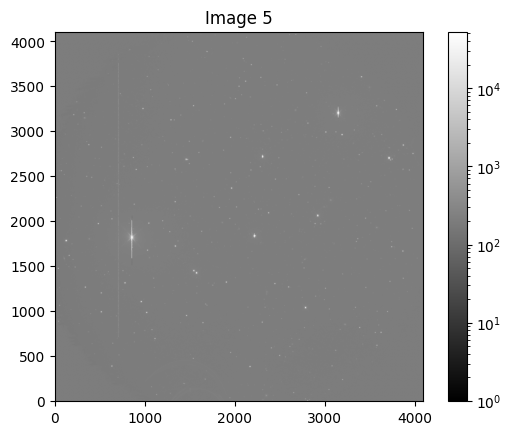

Date of above observation is: [2021.0, 7.0, 13.0, 22.0, 5.0, 16.046]


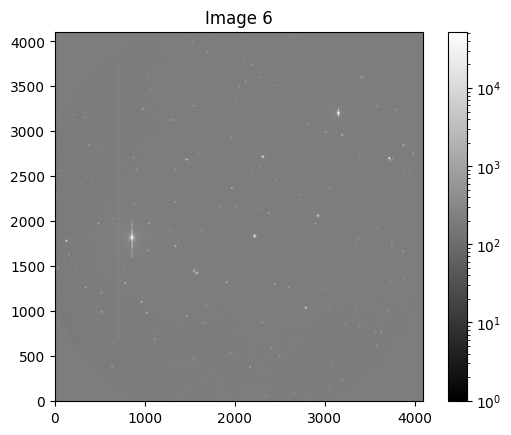

Date of above observation is: [2021.0, 7.0, 13.0, 22.0, 10.0, 24.98]


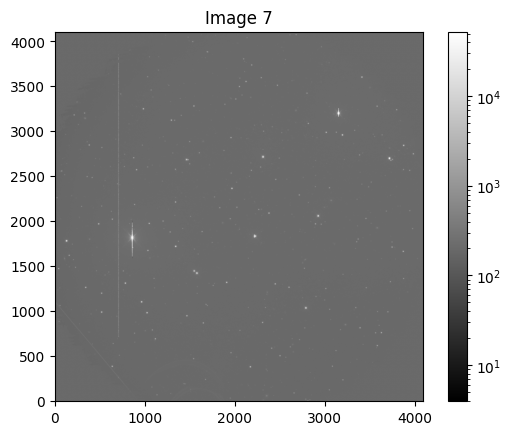

Date of above observation is: [2021.0, 7.0, 13.0, 22.0, 15.0, 33.914]


In [81]:
for i in range(len(filesSortedByDate)):
    if (abs(datesOfObservationDateValSorted[i][2] - 13.0) < 0.1):
        imageData = filesSortedByDate[i][0].data
        plt.imshow(imageData, cmap='gray', norm=LogNorm(), origin='lower')

        plt.colorbar()
        plt.title(f"Image {i+1}")
        plt.show()
        print(f"Date of above observation is: {datesOfObservationDateValSorted[i]}")
        # filesSortedByDate[i][0].header
# plt.imshow(image1Data, cmap='gray', norm=LogNorm(), origin='lower')
# plt.colorbar()
# plt.show()

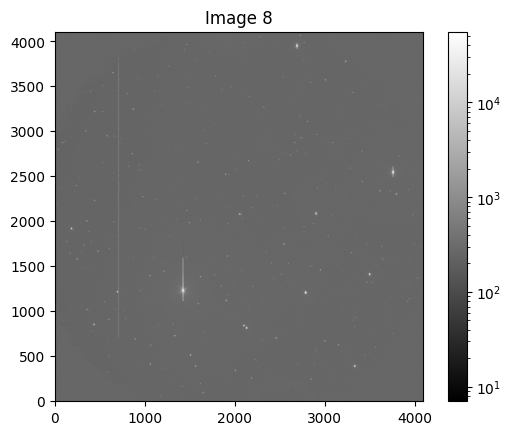

Date of above observation is: [2021.0, 7.0, 14.0, 21.0, 39.0, 19.746]


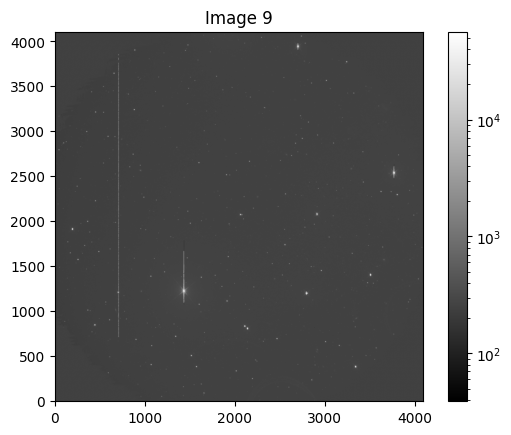

Date of above observation is: [2021.0, 7.0, 14.0, 22.0, 0.0, 20.444]


In [82]:
for i in range(len(filesSortedByDate)):
    if (abs(datesOfObservationDateValSorted[i][2] - 14.0) < 0.1):
        imageData = filesSortedByDate[i][0].data
        plt.imshow(imageData, cmap='gray', norm=LogNorm(), origin='lower')

        plt.colorbar()
        plt.title(f"Image {i+1}")
        plt.show()
        print(f"Date of above observation is: {datesOfObservationDateValSorted[i]}")

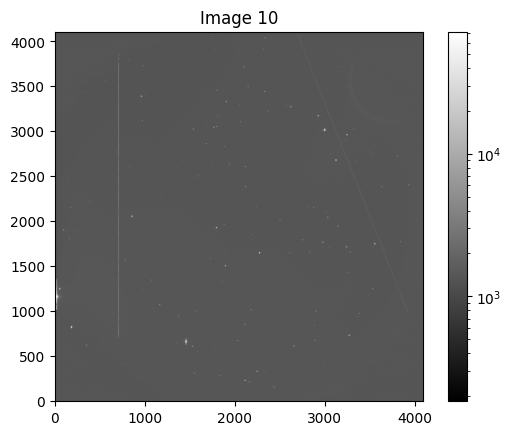

Date of above observation is: [2021.0, 7.0, 21.0, 19.0, 14.0, 11.345]


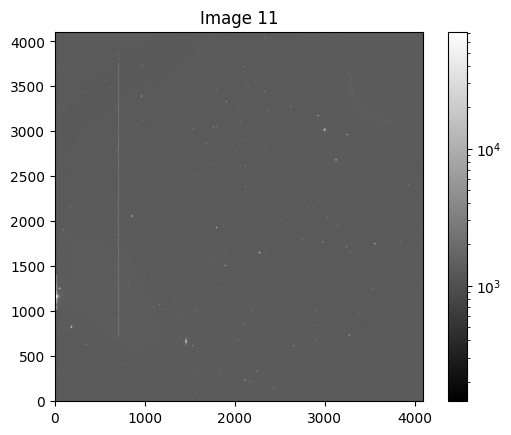

Date of above observation is: [2021.0, 7.0, 21.0, 19.0, 19.0, 20.421]


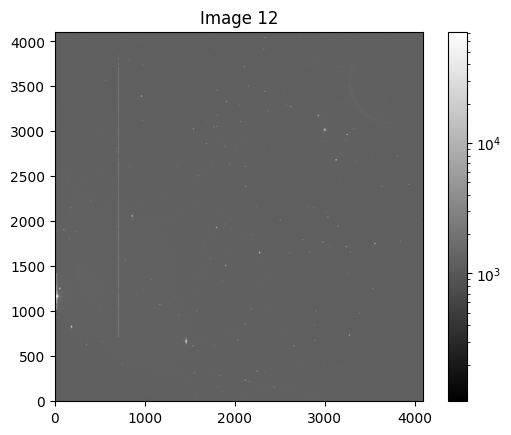

Date of above observation is: [2021.0, 7.0, 21.0, 19.0, 24.0, 29.359]


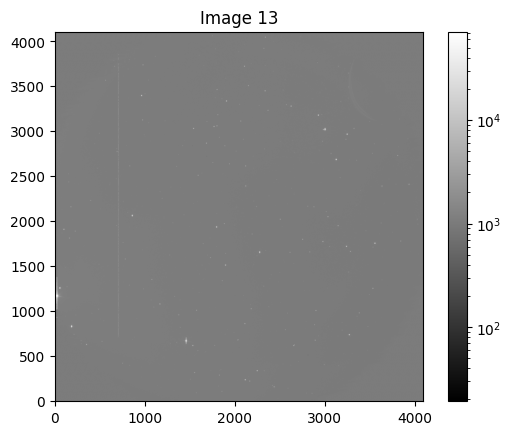

Date of above observation is: [2021.0, 7.0, 21.0, 19.0, 34.0, 47.216]


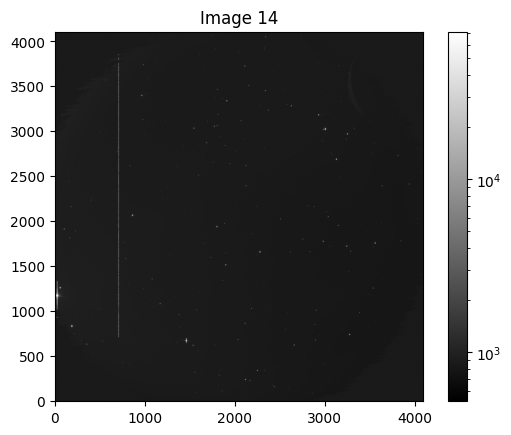

Date of above observation is: [2021.0, 7.0, 21.0, 19.0, 45.0, 5.08]


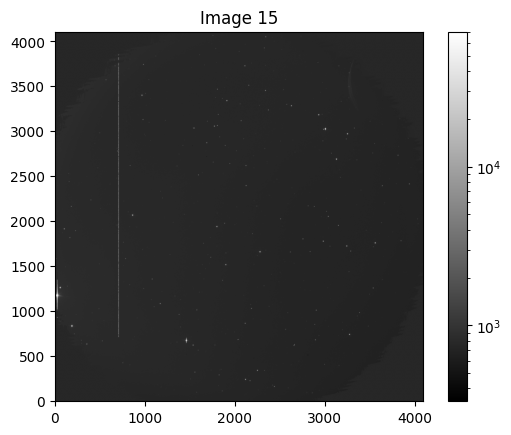

Date of above observation is: [2021.0, 7.0, 21.0, 19.0, 50.0, 14.013]


In [83]:
for i in range(len(filesSortedByDate)):
    if (abs(datesOfObservationDateValSorted[i][2] - 21.0) < 0.1):
        imageData = filesSortedByDate[i][0].data
        plt.imshow(imageData, cmap='gray', norm=LogNorm(), origin='lower')

        plt.colorbar()
        plt.title(f"Image {i+1}")
        plt.show()
        print(f"Date of above observation is: {datesOfObservationDateValSorted[i]}")

In [84]:
headerThis: astropy.io.fits.header.Header = filesSortedByDate[0][0].header
headerThis['AVERAGE']

1165.24240947304

In [85]:
a= filesSortedByDate[0][0].data - filesSortedByDate[0][0].header['AVERAGE']

In [86]:
b = filesSortedByDate[1][0].data - filesSortedByDate[1][0].header['AVERAGE']

In [87]:
EPSILON = 1e-10
a_negativeRemoved = np.copy(a)
a_negativeRemoved[a_negativeRemoved < EPSILON] = EPSILON
b_negativeRemoved = np.copy(b)
b_negativeRemoved[b_negativeRemoved < EPSILON] = EPSILON


In [88]:
a_infNegRemoved = np.copy(a_negativeRemoved)
b_infNegRemoved = np.copy(b_negativeRemoved)
a_infNegRemoved[np.isinf(a_infNegRemoved)] = 0
b_infNegRemoved[np.isinf(b_infNegRemoved)] = 0

In [89]:
a_infRemoved = np.copy(a)
a_infRemoved[np.isinf(a)] = 0
b_infRemoved = np.copy(b)
b_infRemoved[np.isinf(b)] = 0

In [90]:
c = a_infRemoved - b_infRemoved
c_adjusted = c - np.min(c) + EPSILON
c_adjusted -= np.mean(c_adjusted)  # Subtract the mean to center the data around zero
c_adjusted[c_adjusted < EPSILON] = EPSILON  # Set values below EPSILON to EPSILON
print(f"Min value of c_adjusted: {np.min(c_adjusted)}")
print(f"Average value of c_adjusted: {np.mean(c_adjusted)}")

Min value of c_adjusted: 1.000000013351432e-10
Average value of c_adjusted: 34.162269592285156


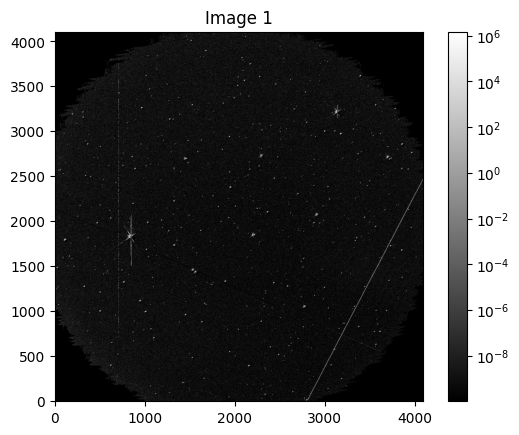

Date of above observation is: [2021.0, 7.0, 13.0, 21.0, 39.0, 12.742]


In [91]:
# imageData =( filesSortedByDate[0][0].data - filesSortedByDate[0][0].header['AVERAGE']) - (filesSortedByDate[1][0].data - filesSortedByDate[1][0].header['AVERAGE'])
# imageData = b_infNegRemoved - a_infNegRemoved
imageData = c_adjusted
plt.imshow(imageData, cmap='gray', norm=LogNorm(), origin='lower')

plt.colorbar()
plt.title(f"Image {0+1}")
plt.show()
print(f"Date of above observation is: {datesOfObservationDateValSorted[0]}")    

In [92]:
# np.seterr(all='raise')
# c = np.zeros_like(a)  # Initialize c with the same shape as a
# for i in range(len(a)):
#     for j in range(len(a[i])):
#         # # if runtimewarning, print values 
#         # if (np.isnan(a[i][j]) or np.isnan(b[i][j])):
#         #     print(f"NaN encountered at position ({i}, {j}): a={a[i][j]}, b={b[i][j]}")
#         try:
#             c[i][j] = a[i][j] - b[i][j]
#         except:
#             print(f"Error encountered at position ({i}, {j}): a={a[i][j]}, b={b[i][j]}")
#             c[i][j] = 0


In [93]:
filesSortedByDate[0][0].header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4108                                                  
HISTORY Created with RTS2 version 0.9.5 build on May 12 2020 19:07:30.          
CTIME   =           1626212352 / exposure start (seconds since 1.1.1970)        
USEC    =               742874 / exposure start micro seconds                   
JD      =     2459409.40222445 / Modified Julian Date                           
DATE-OBS= '2021-07-13T21:39:12.742' / start of exposure                         
EXPOSURE=                 300. / exposure length in seconds                     
EXPTIME =                 300. / exposure length in seconds                     
INSTRUME= 'RTS2 spectograph'

In [94]:
i0 = filesSortedByDate[0][0].data
ioH: astropy.io.fits.Header = filesSortedByDate[0][0].header
print(ioH['STDEV'])

917.93803041668


In [95]:
mean, median, std = sigma_clipped_stats(i0, sigma=3.0)
print(std)

13.9729395


In [96]:
finder = DAOStarFinder(fwhm=3.0, threshold=3*ioH['STDEV'])
sources = finder(i0 - median)

/home/odin/Code/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/home/odin/Code/lib/python3.12/site-packages/photutils/detection/daofinder.py:922: RuntimeWarning: invalid value encountered in subtract
  hx_numer = data_kern_sum - (data_sum * kern_sum) / wt_sum
/home/odin/Code/lib/python3.12/site-packages/photutils/detection/daofinder.py:871: RuntimeWarning: invalid value encountered in multiply
  data_sum_1d * kern_sums['dkern_dx'] * wt, axis=1)
/home/odin/Code/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/home/odin/Code/lib/python3.12/site-packages/photutils/detection/daofinder.py:872: RuntimeWarning: invalid value encountered in multiply
  data_dx_sum = np.sum(data_sum_1d * dxx * wt, axis=1)
/home/odin/Code/lib/python3.12/site-packages/pho

In [97]:
# Extract positions
len(sources)

122

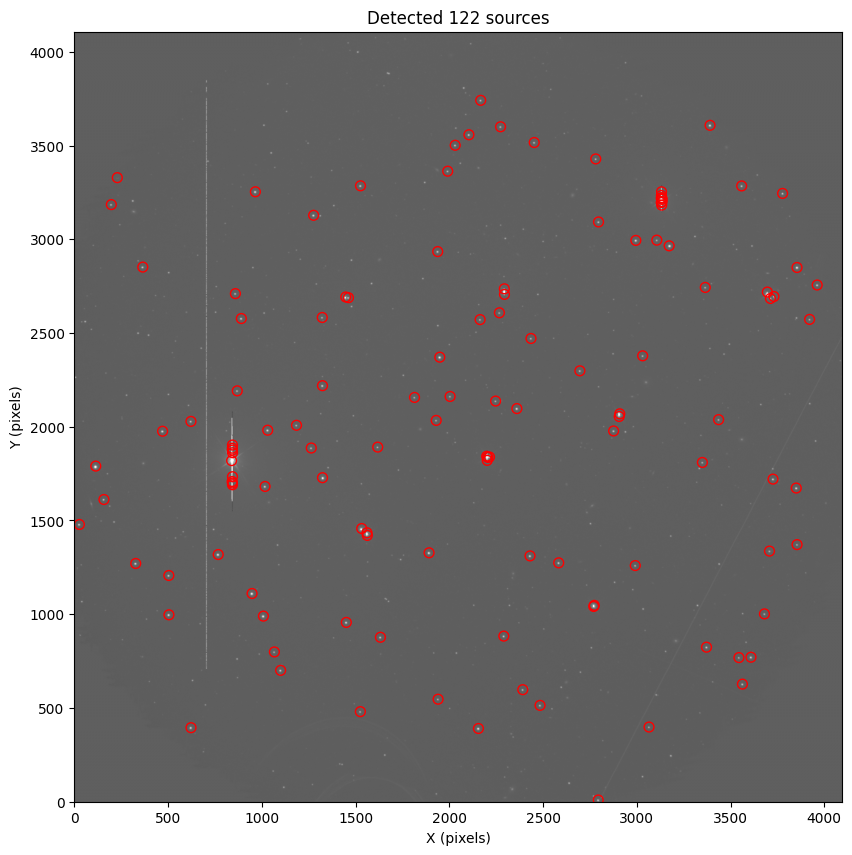

In [98]:
fig,ax = plt.subplots( figsize=(10, 10))
ax.imshow(i0, cmap='gray', norm=LogNorm(), origin='lower')
ax.scatter(sources['xcentroid'], sources['ycentroid'], s=50, edgecolor='red', facecolor='none')
ax.set_title(f"Detected {len(sources)} sources")
ax.set_xlabel("X (pixels)")
ax.set_ylabel("Y (pixels)")
plt.show()

925.516017823816
Detected 99 sources in the second image.
Filtered to 20 sources with flux above 27664.02734375.


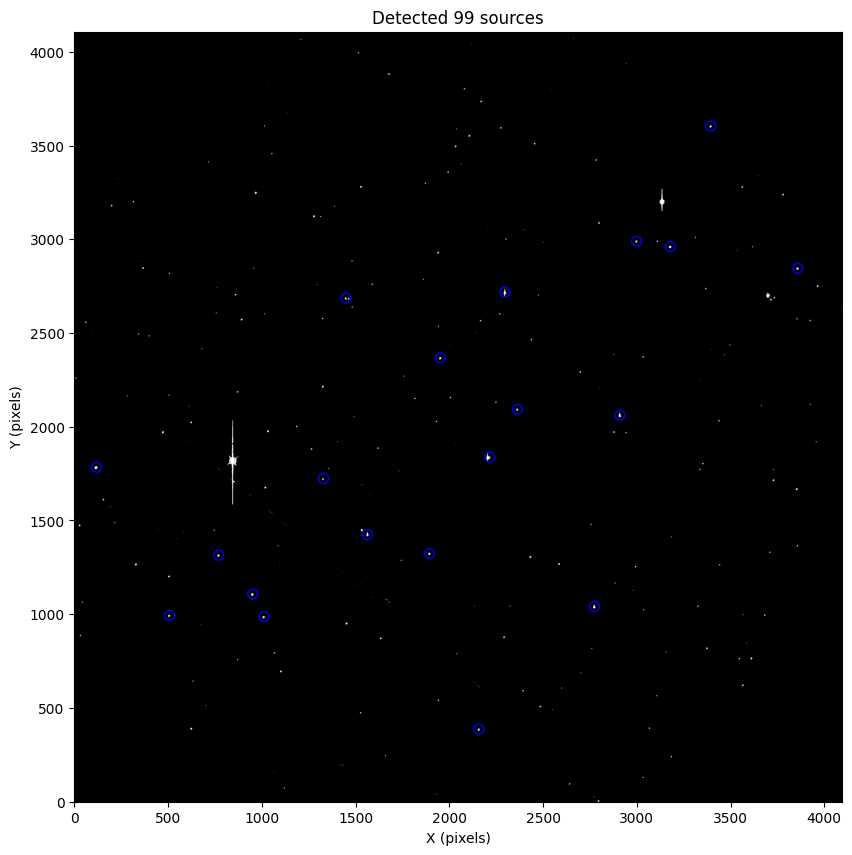

In [119]:
i1 = filesSortedByDate[2][0].data - filesSortedByDate[2][0].header['AVERAGE']
i1[i1 < EPSILON] = EPSILON
i1[np.isinf(i1)] = 0
ioH: astropy.io.fits.Header = filesSortedByDate[2][0].header
print(ioH['STDEV'])
mean, median, std = sigma_clipped_stats(i1, sigma=3.0)
finder = DAOStarFinder(fwhm=10.0, threshold=3.*ioH['STDEV'])
sources = finder(i1 - median)
targetForFiltering = 'peak'
fluxDesc = np.sort(np.array(sources[targetForFiltering]))[::-1]
thresholdFlux = fluxDesc[20]
mask = sources[targetForFiltering] > thresholdFlux
sourcesFiltered = sources[mask]
print(f"Detected {len(sources)} sources in the second image.")
print(f"Filtered to {len(sourcesFiltered)} sources with flux above {thresholdFlux}.")
fig,ax = plt.subplots( figsize=(10, 10))
ax.imshow(i1, cmap='gray', norm=LogNorm(), origin='lower')
# ax.scatter(sources['xcentroid'], sources['ycentroid'], s=50, edgecolor='red', facecolor='none')
ax.scatter(sourcesFiltered['xcentroid'], sourcesFiltered['ycentroid'], s=50, edgecolor='blue', facecolor='none')
ax.set_title(f"Detected {len(sources)} sources")
ax.set_xlabel("X (pixels)")
ax.set_ylabel("Y (pixels)")
plt.show()

925.516017823816
Detected 99 sources in the second image.
Filtered to 20 sources with flux above 27664.02734375.


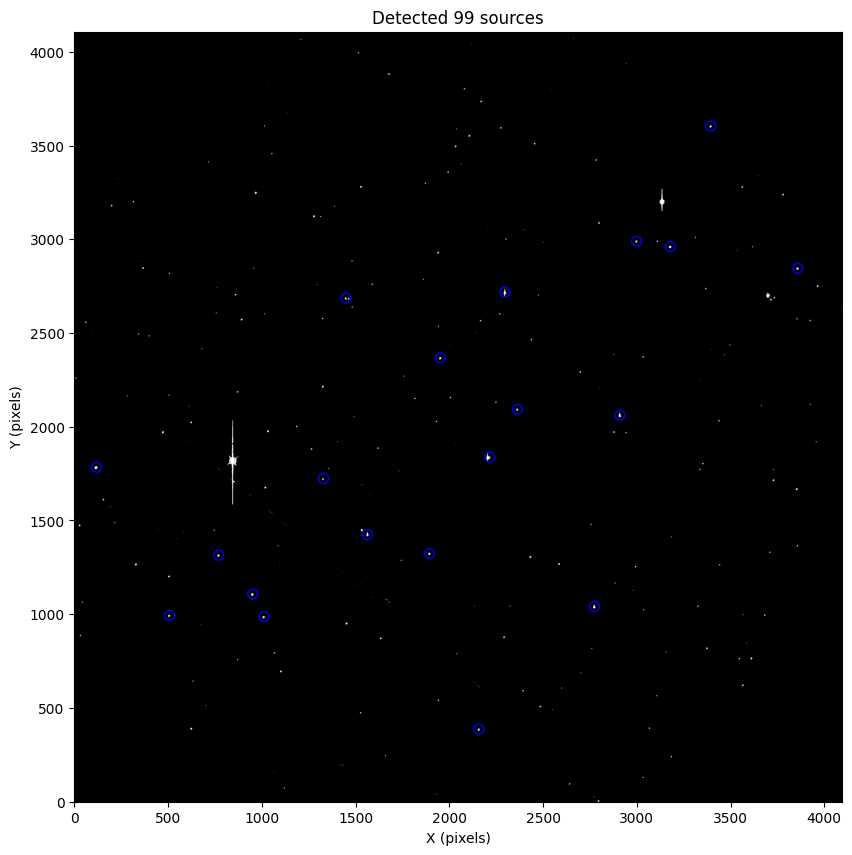

In [118]:
i1 = filesSortedByDate[2][0].data - filesSortedByDate[2][0].header['AVERAGE']
i1[i1 < EPSILON] = EPSILON
i1[np.isinf(i1)] = 0
ioH: astropy.io.fits.Header = filesSortedByDate[2][0].header
print(ioH['STDEV'])
mean, median, std = sigma_clipped_stats(i1, sigma=3.0)
finder = DAOStarFinder(fwhm=10.0, threshold=3.*ioH['STDEV'])
sources = finder(i1 - median)
targetForFiltering = 'peak'
fluxDesc = np.sort(np.array(sources[targetForFiltering]))[::-1]
thresholdFlux = fluxDesc[20]
mask = sources[targetForFiltering] > thresholdFlux
sourcesFiltered = sources[mask]
print(f"Detected {len(sources)} sources in the second image.")
print(f"Filtered to {len(sourcesFiltered)} sources with flux above {thresholdFlux}.")
fig,ax = plt.subplots( figsize=(10, 10))
ax.imshow(i1, cmap='gray', norm=LogNorm(), origin='lower')
# ax.scatter(sources['xcentroid'], sources['ycentroid'], s=50, edgecolor='red', facecolor='none')
ax.scatter(sourcesFiltered['xcentroid'], sourcesFiltered['ycentroid'], s=50, edgecolor='blue', facecolor='none')
ax.set_title(f"Detected {len(sources)} sources")
ax.set_xlabel("X (pixels)")
ax.set_ylabel("Y (pixels)")
plt.show()

In [ ]:
def processAndIsolateStars(openedFitsFile, fwhm=10.0, thresholdMultiplier=3.0, targetForFiltering='peak', numSourcesToKeep=20, mainListToAppendTo = None):
    i = openedFitsFile[0].data - openedFitsFile[0].header['AVERAGE']
    i[i < EPSILON] = EPSILON
    i[np.isinf(i)] = 0
    ioH: astropy.io.fits.Header = openedFitsFile[0].header
    print(ioH['STDEV'])
    mean, median, std = sigma_clipped_stats(i, sigma=3.0)
    finder = DAOStarFinder(fwhm=fwhm, threshold=thresholdMultiplier*ioH['STDEV'])
    sources = finder(i - median)
    fluxDesc = np.sort(np.array(sources[targetForFiltering]))[::-1]
    thresholdFlux = fluxDesc[np.min(numSourcesToKeep, len(fluxDesc)-1)]
    mask = sources[targetForFiltering] > thresholdFlux
    sourcesFiltered = sources[mask]
    if mainListToAppendTo is not None:
        mainListToAppendTo.append(sourcesFiltered)
    print(f"Detected {len(sources)} sources in the image.")
    print(f"Filtered to {len(sourcesFiltered)} sources with flux above {thresholdFlux}.")
    
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(i, cmap='gray', norm=LogNorm(), origin='lower')
    ax.scatter(sourcesFiltered['xcentroid'], sourcesFiltered['ycentroid'], s=50, edgecolor='blue', facecolor='none')
    ax.set_title(f"Detected {len(sources)} sources")
    ax.set_xlabel("X (pixels)")
    ax.set_ylabel("Y (pixels)")
    plt.show()
    
    return sourcesFiltered



Processing file 1/15: 20210713213912-742-RA.wcs.proc.fits
917.93803041668
Detected 93 sources in the image.
Filtered to 20 sources with flux above 30703.583984375.


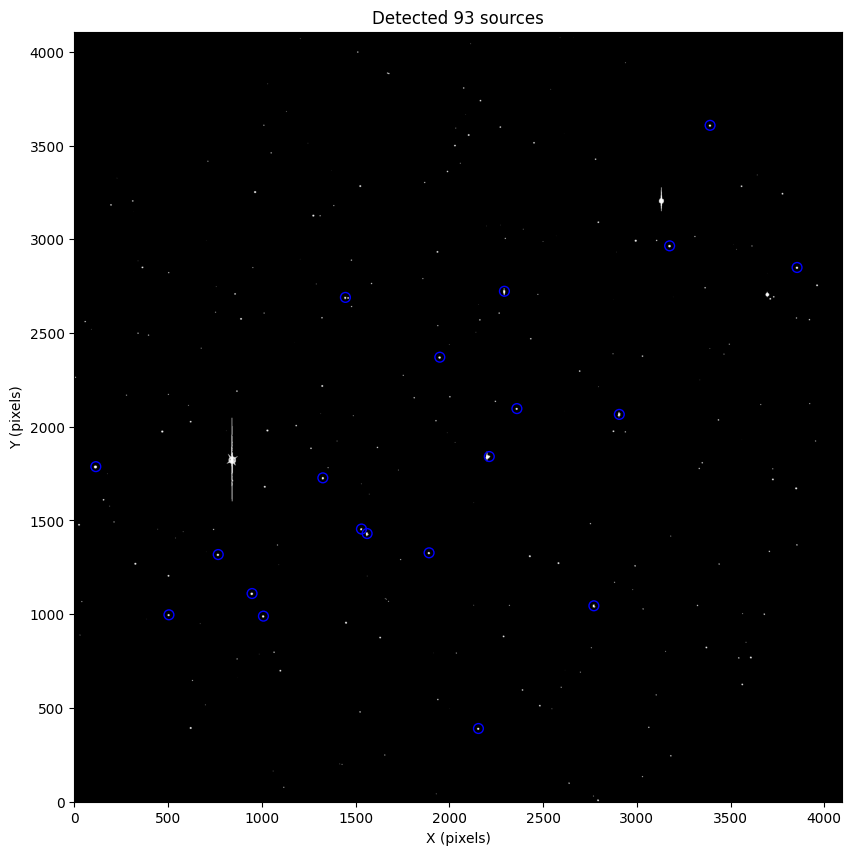

Processing file 2/15: 20210713214440-179-RA.wcs.proc.fits
930.930929293218
Detected 72 sources in the image.
Filtered to 20 sources with flux above 32303.560546875.


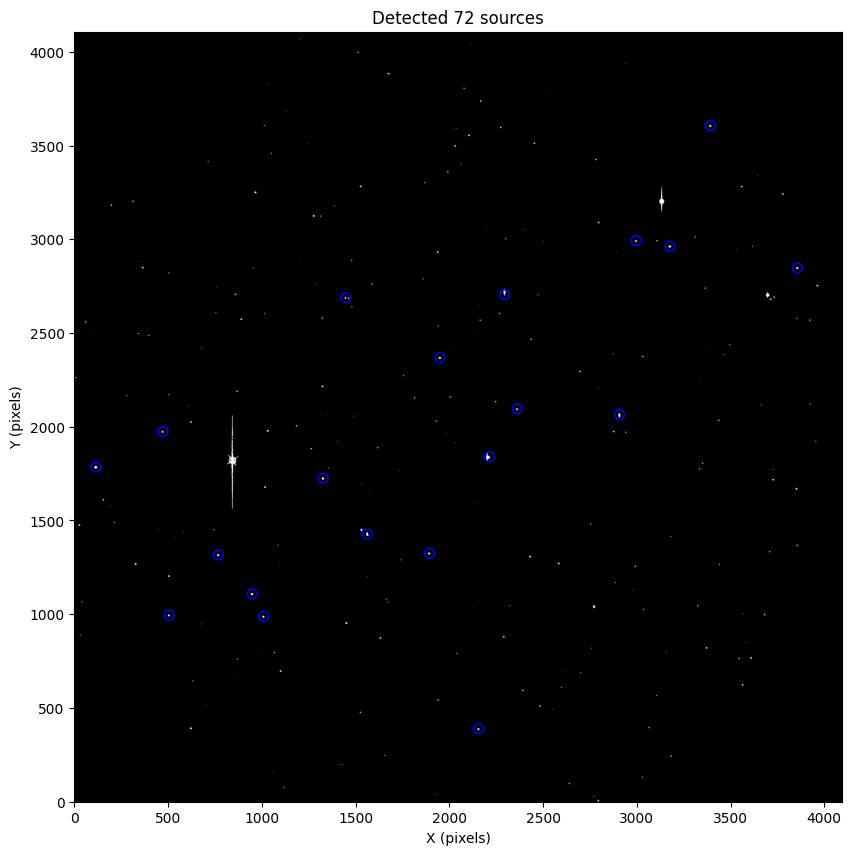

Processing file 3/15: 20210713214949-265-RA.wcs.proc.fits
925.516017823816
Detected 99 sources in the image.
Filtered to 20 sources with flux above 27664.02734375.


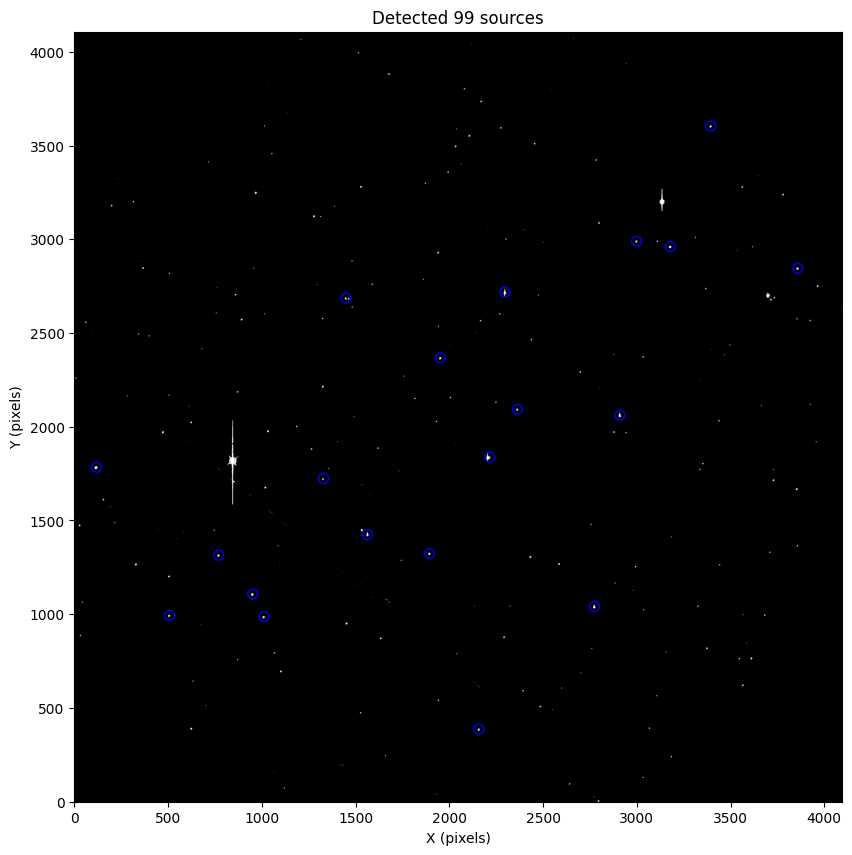

Processing file 4/15: 20210713215458-181-RA.wcs.proc.fits
922.512209226998
Detected 26 sources in the image.
Filtered to 20 sources with flux above 30247.1640625.


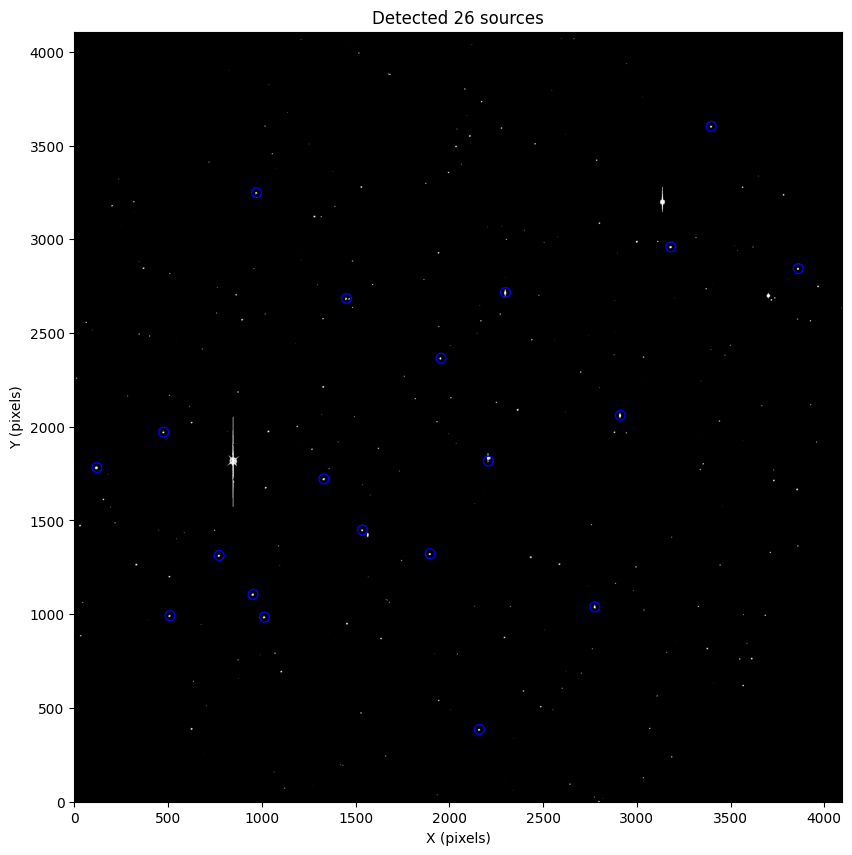

Processing file 5/15: 20210713220516-046-RA.wcs.proc.fits
924.650012949313
Detected 86 sources in the image.
Filtered to 20 sources with flux above 28433.361328125.


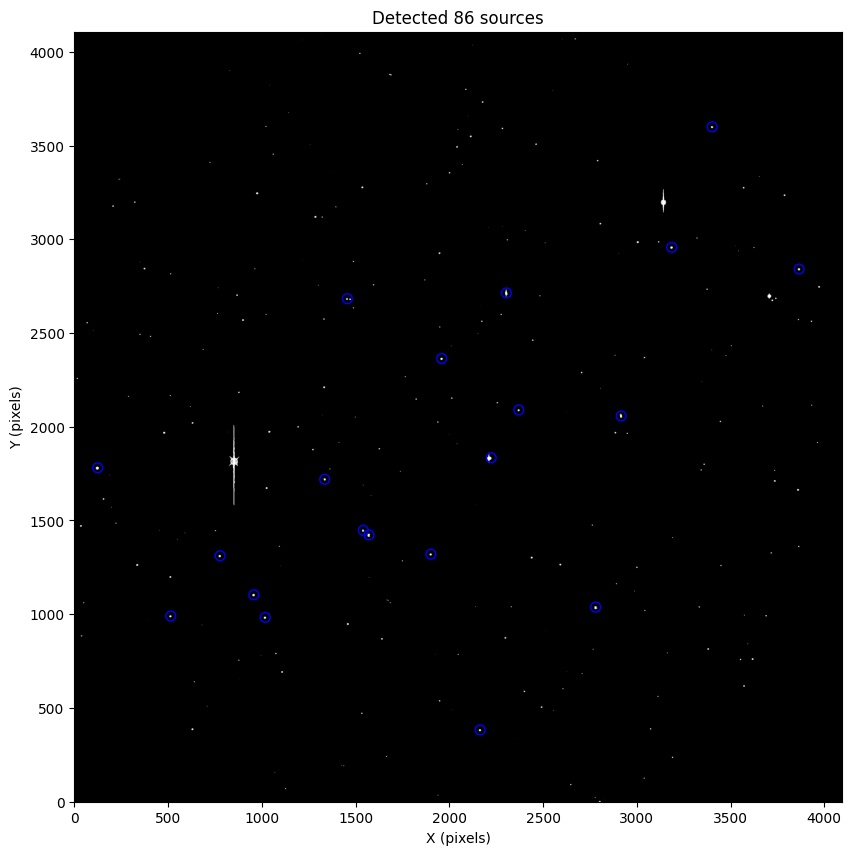

Processing file 6/15: 20210713221024-980-RA.wcs.proc.fits
897.762676588601
Detected 101 sources in the image.
Filtered to 20 sources with flux above 21932.208984375.


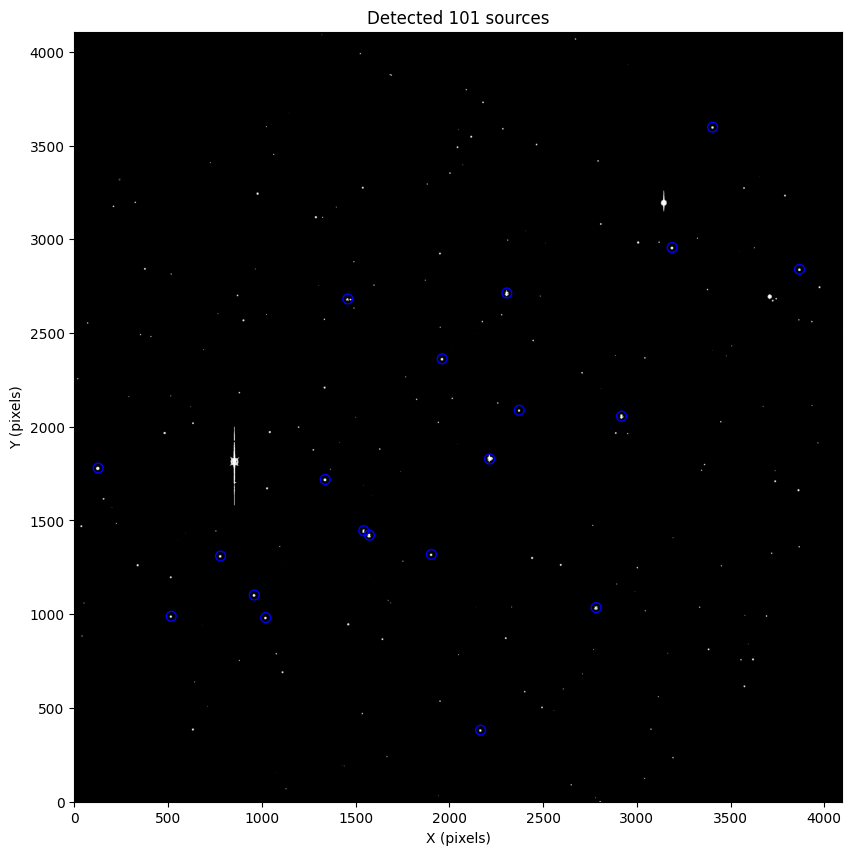

Processing file 7/15: 20210713221533-914-RA.wcs.proc.fits
872.747671604881
Detected 99 sources in the image.
Filtered to 20 sources with flux above 20363.56640625.


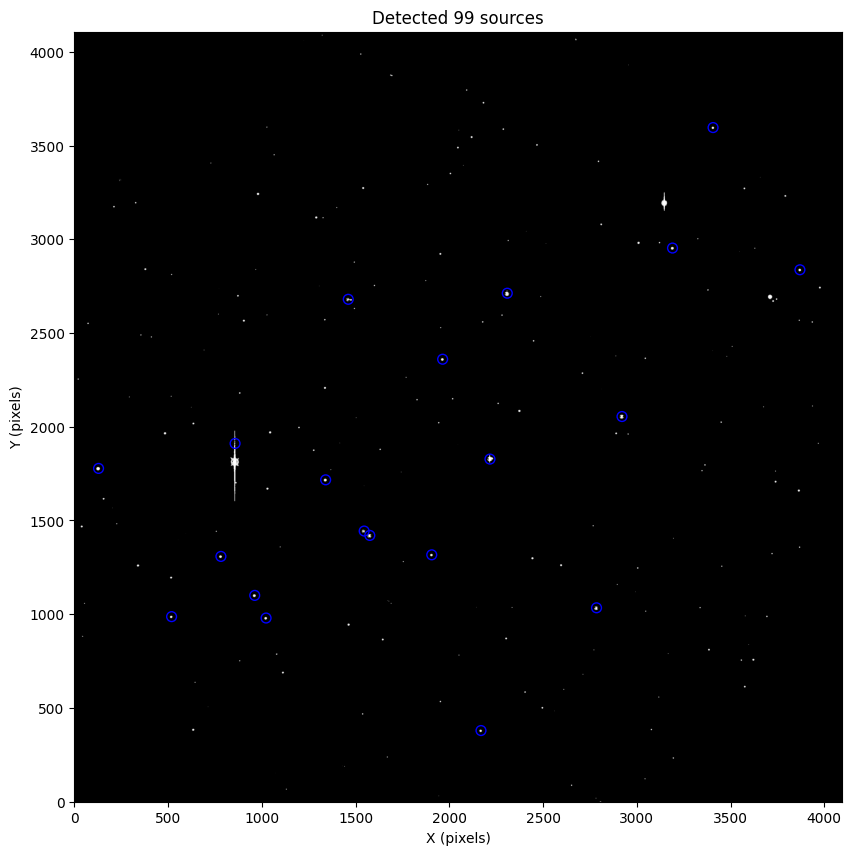

Processing file 8/15: 20210714213919-746-RA.wcs.proc.fits
967.474271378806
Detected 42 sources in the image.
Filtered to 20 sources with flux above 34996.94140625.


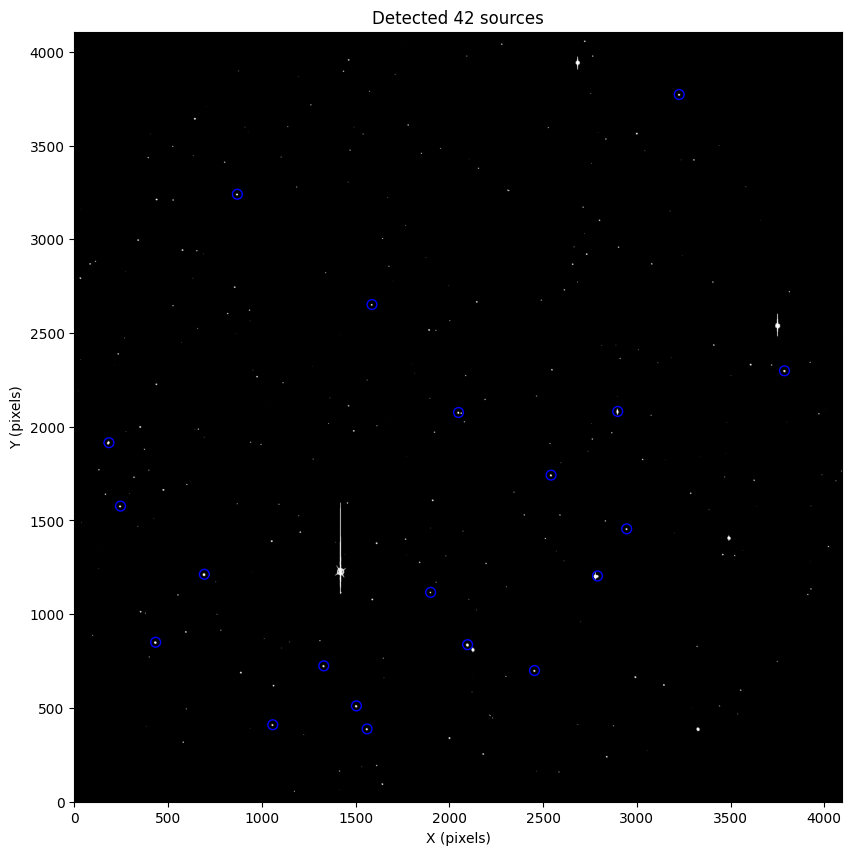

Processing file 9/15: 20210714220020-444-RA.wcs.proc.fits
973.244286620721
Detected 31 sources in the image.
Filtered to 20 sources with flux above 36719.74609375.


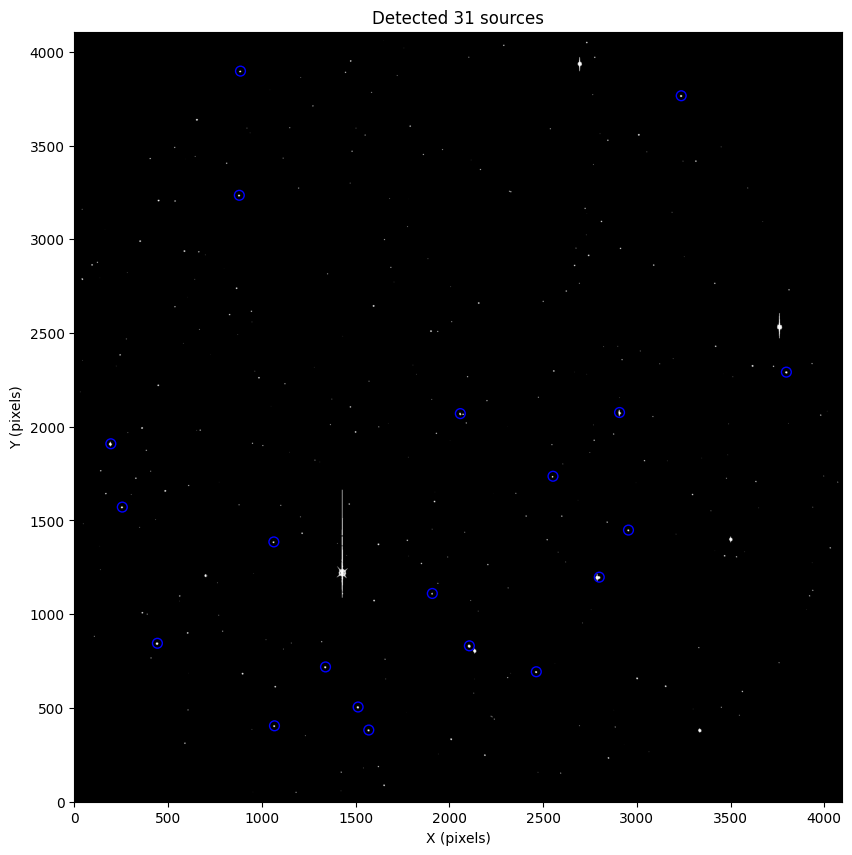

Processing file 10/15: 20210721191411-345-RA.wcs.proc.fits
943.506342209633
Detected 108 sources in the image.
Filtered to 20 sources with flux above 45122.796875.


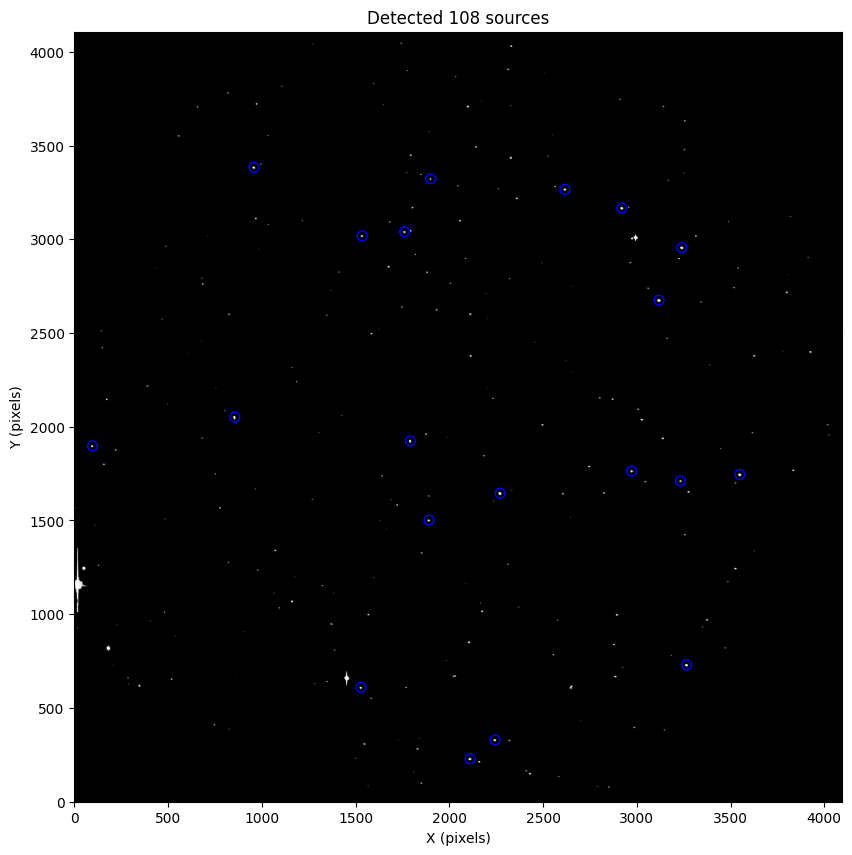

Processing file 11/15: 20210721191920-421-RA.wcs.proc.fits
941.405375266606
Detected 99 sources in the image.
Filtered to 20 sources with flux above 42103.8671875.


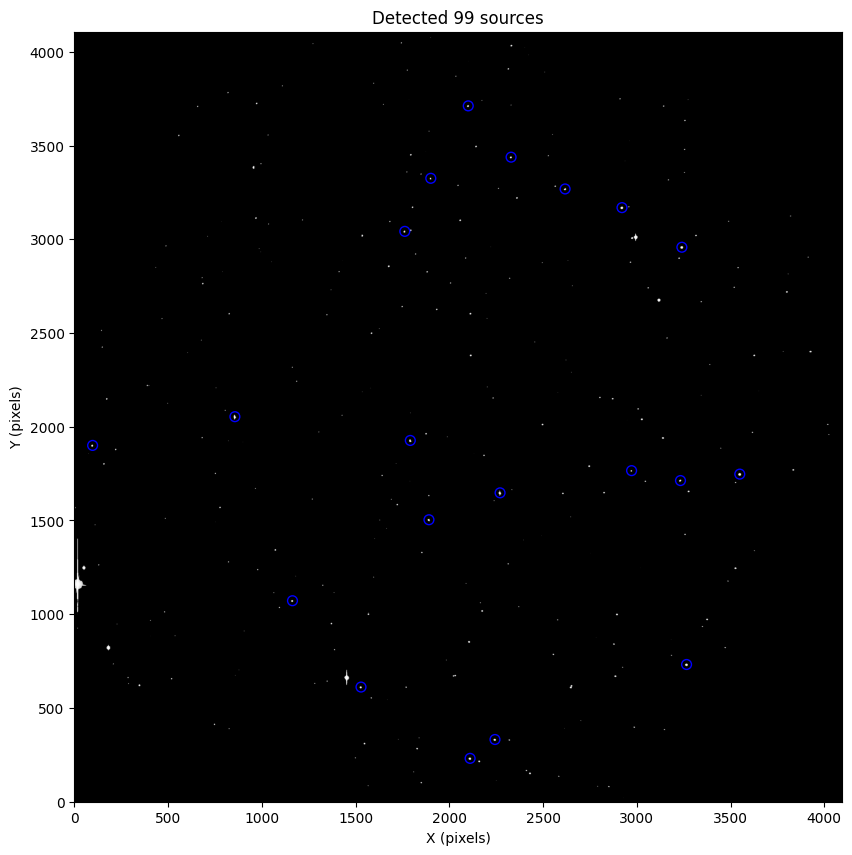

Processing file 12/15: 20210721192429-359-RA.wcs.proc.fits
928.39842911415
Detected 64 sources in the image.
Filtered to 20 sources with flux above 38147.7734375.


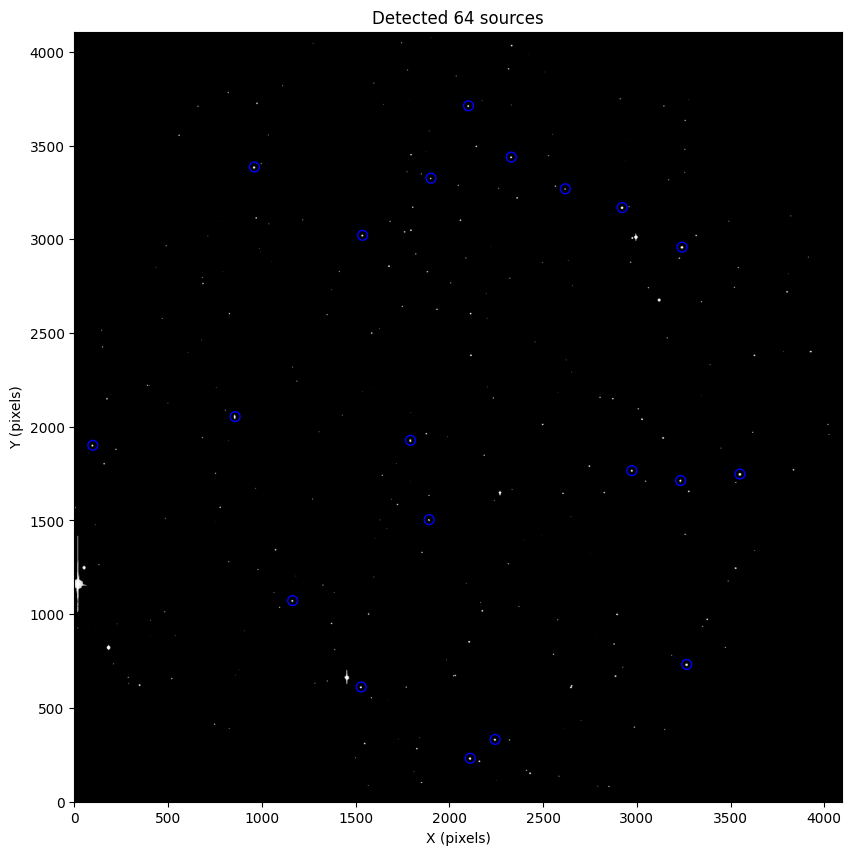

Processing file 13/15: 20210721193447-216-RA.wcs.proc.fits
885.046002552886
Detected 37 sources in the image.
Filtered to 20 sources with flux above 46245.9609375.


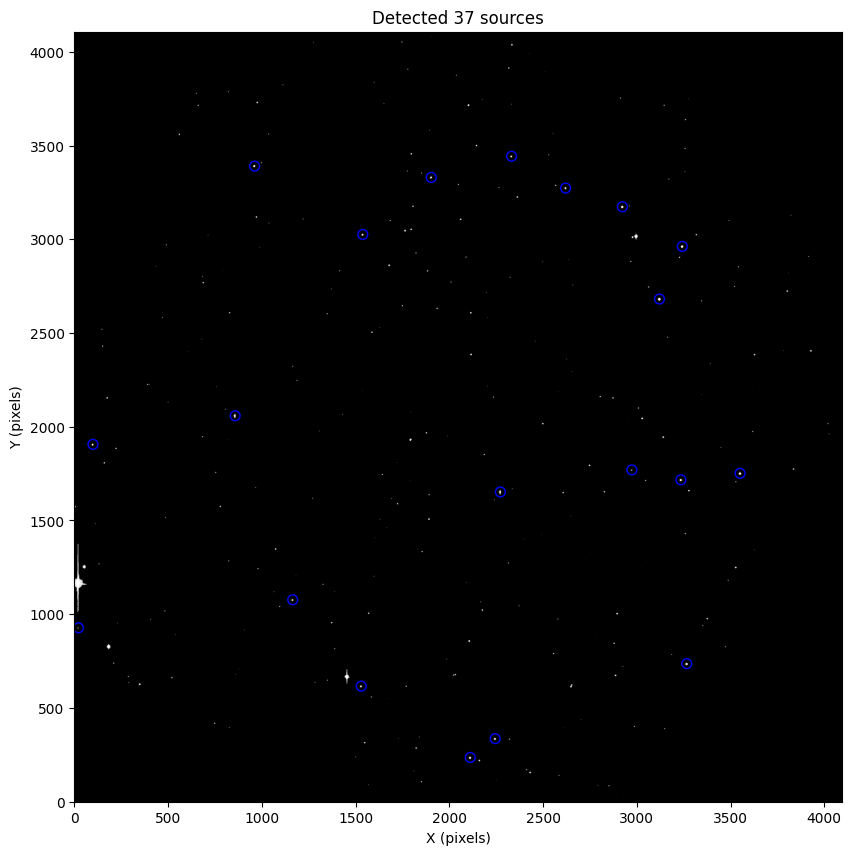

Processing file 14/15: 20210721194505-080-RA.wcs.proc.fits
829.938813895837
Detected 22 sources in the image.
Filtered to 20 sources with flux above 45420.79296875.


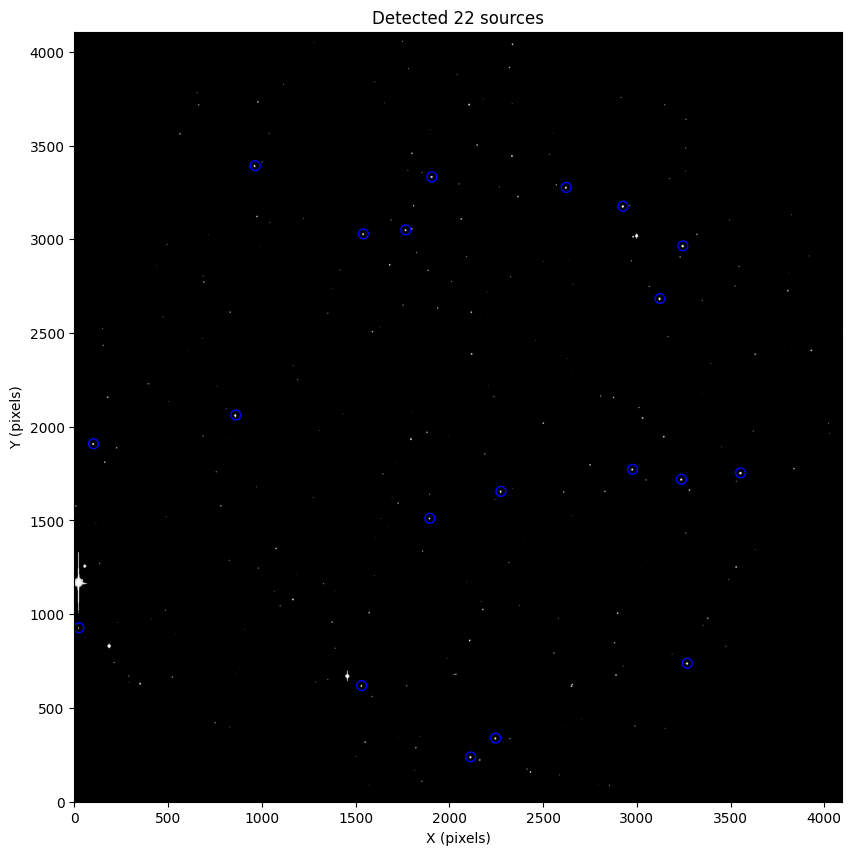

Processing file 15/15: 20210721195014-013-RA.wcs.proc.fits
784.428116557496


IndexError: index 20 is out of bounds for axis 0 with size 19

In [ ]:
sourcesFilteredList = []
for i in range(len(filesSortedByDate)):
    print(f"Processing file {i+1}/{len(filesSortedByDate)}: {allDataFileNames[argsortedIndices[i]]}")
    processAndIsolateStars(filesSortedByDate[i], fwhm=10.0, thresholdMultiplier=3.0, targetForFiltering='peak', numSourcesToKeep=20, mainListToAppendTo=sourcesFilteredList)

In [126]:
sources[0]

id,x_centroid,y_centroid,sharpness,roundness1,roundness2,n_pixels,peak,flux,mag,daofind_mag
int64,float64,float64,float64,float32,float64,int64,float32,float64,float64,float64
1,2797.188840152267,4.704906095621083,0.46821340877537976,0.17902716,0.25403949551594057,169,5877.87,194516.76916503906,-13.22239261880615,-2.1852115030908865


In [ ]:


def findMovementOfImage(sourcesList, thresholdToIgnore) -> np.array:
    numImages = len(sourcesList)
    for imagePairIdx in range(numImages - 1):
        sourcesReference = sourcesList[imagePairIdx]
        sourcesNew = sourcesList[imagePairIdx + 1]
        numSourcesReference = len(sourcesReference)
        numSourcesNew = len(sourcesNew)
        for sourceIdx in range(numSourcesReference):
            sourceRef = sourcesReference[sourceIdx]
            xRef = sourceRef['xcentroid']
            yRef = sourceRef['ycentroid']
            
            for


5877.87
3901.2212
4329.1987
38093.84
22141.625
4130.4976
4753.8667
9171.362
4923.4165
6739.5454
9096.036
